# PSET 0 — Warm-Up + Background
**Neuro 240 / Phys 240**

This is an *optional* warm-up to get comfortable with the tools used in this course: data analysis, training neural networks (by hand and in TensorFlow), and image classification.

Format: **fill-in-the-blank**. Look for `# TODO` markers and `...` gaps.

In [2]:
# Global setup
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.datasets import load_iris, fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

np.random.seed(0)
tf.random.set_seed(0)

## Problem 1 — Data Analysis (20 points)

Goal: basic data exploration. Load the Iris dataset, inspect its structure, and visualize class separability in feature space.

In [3]:
iris = load_iris(as_frame=True)
df = iris.frame

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


#### a) Annotating Data (1 points)

The data above contains a target variable corresponding to the following labels. In this first step, annotate the dataframe based on the following label map:

0 = setosa \
1 = versicolor \
2 = virginica


hint: Use df.map()


In [ ]:
#TODO 

df["species"] = ... 

#### b) Descriptive Statistics (2 points)

Plot ths distributions of each feature as a function of target label. Your output should be a 3 x 4 plot with histograms

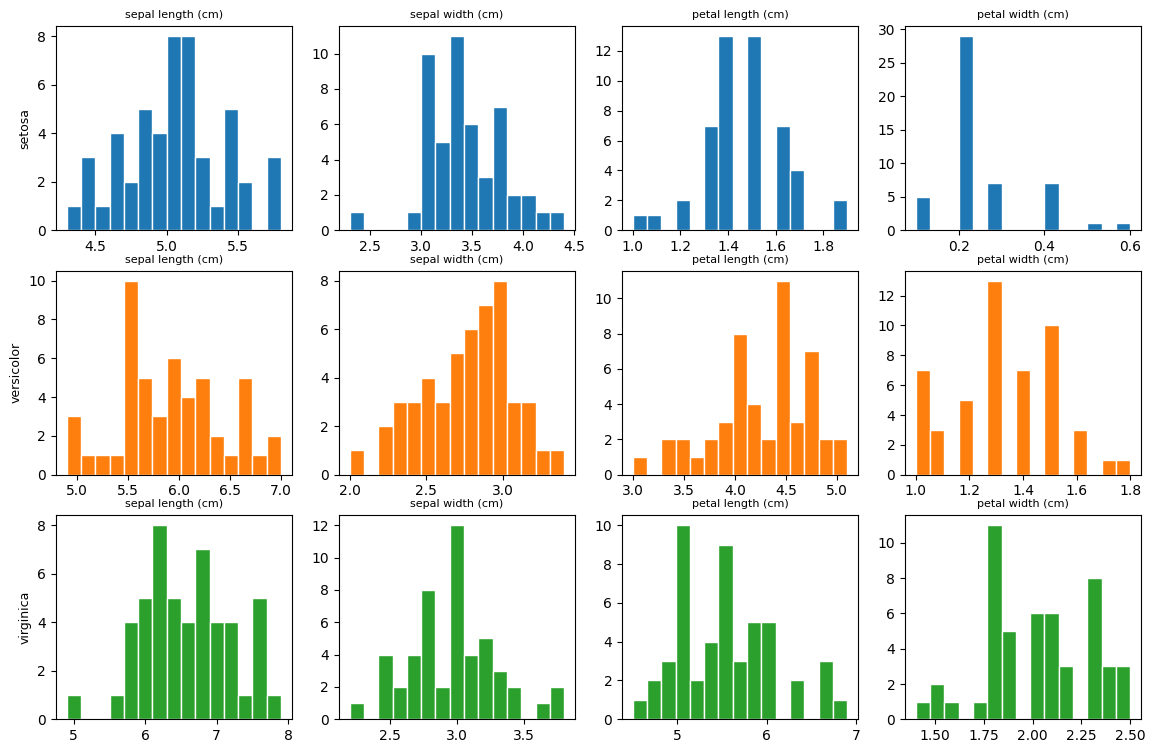

In [ ]:
#TODO
features = ...
species  = ...


fig, axes = plt.subplots(3, 4, figsize=(14, 9))

for i, sp in enumerate(sorted(species)):
    subset = df[df["species"] == sp]
    for j, feat in enumerate(features):
        ax = axes[i, j]
        ax.hist(..., bins=15, color=f"C{i}", edgecolor="white")
        ax.set_title(feat, fontsize=8)
        if j == 0:
            ax.set_ylabel(sp, fontsize=9)

plt.show()

#### c) Scatter Plot (2 points)

Select two feature variables and produce a scatter plot of each data point. Try to base your selection on the descriptive statistics observed above. Label each data point by the corresponding species label. Hint: df.describe may be helpful for selecting features.

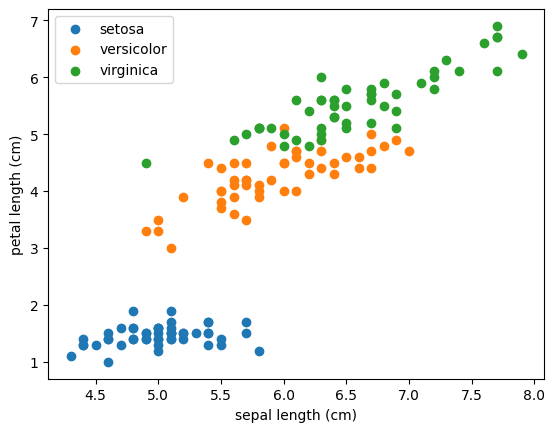

In [ ]:
#TODO

for i, sp in enumerate(sorted(df["species"].unique())):
    subset = df[df["species"] == sp]
    plt.scatter(..., ...,
                label=sp, color=f"C{i}")

plt.xlabel(...)
plt.ylabel(...)
plt.legend()
plt.show()

#### d) PCA and sample covariance (10 points)

Center the data and compute the sample covariance $C = \frac{1}{n} X^TX$. Find the first two principle components and produce a scatter plot of the data across these dimensions.

In [ ]:
#TODO

df_centered = ...


X = ...
C = ...

evals, evecs = ...

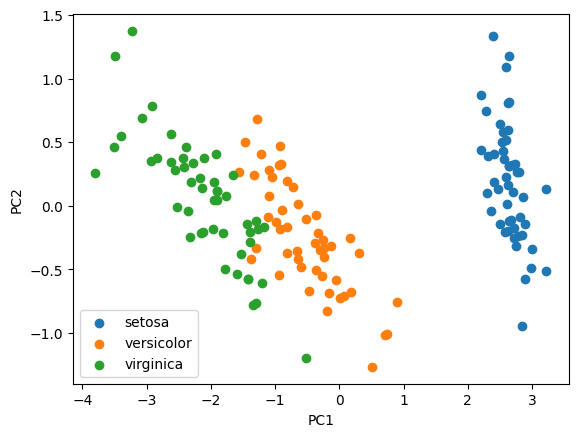

In [ ]:
#TODO
pc1 = ...
pc2 = ...

for i, sp in enumerate(sorted(df["species"].unique())):
    mask = (df["species"] == sp).values
    plt.scatter(pc1[mask], pc2[mask], label=sp, color=f"C{i}")

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend()
plt.show()

#### e) Comparison of Power Iteration Convergence (5 points)

Power iteration is a classical algorithm to compute the top eigen vector of a matrix. For a given symmetric matrix $A$, the algorithm performs the following iteration:

$$
x_{t+1} = \frac{AX_t}{||A x_t||}
$$

Implement this algorithm and plot the convergence in L2 norm to the principal eigenvector of your earlier computed covariance matrix as a function of iteration. Hint: power iteration is ambiguous to signs.

In [ ]:
x= np.ones(len(C))
t_max = 10
xs = np.zeros((len(C), t_max))

#TODO
for t in range(t_max):
    xs[:, t]= ...
    x = ...

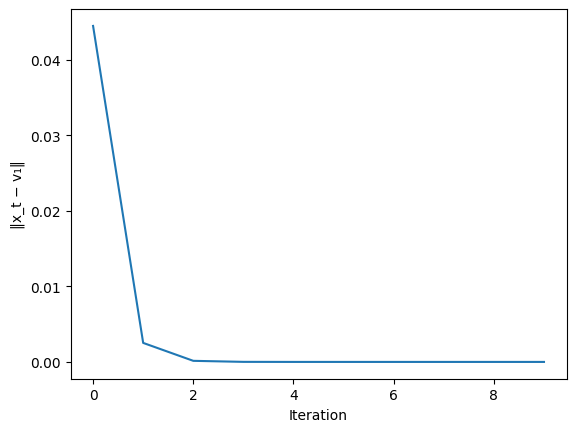

In [ ]:
#TODO
v1 = ...
diffs = [ ...
         for t in range(t_max)]
plt.plot(np.arange(t_max), diffs)
plt.xlabel("Iteration")
plt.ylabel("‖x_t − v₁‖")
plt.show()

## Problem 2 — Training Neural Networks (40 points)

You will (a) derive backprop for a small MLP by hand, (b) implement it in NumPy, then (c) reproduce the same network in TensorFlow and compare.

**Derivation:** write the key expressions for $\partial L/\partial W$ through a one-hidden-layer network in the markdown cell below before coding.

In [49]:
data = fetch_california_housing()
X_train, X_test, y_train, y_test = train_test_split(
    data.data, data.target, test_size=0.2, random_state=0)

scaler = StandardScaler().fit(X_train)
X_train, X_test = scaler.transform(X_train), scaler.transform(X_test)

#### a) Network Diagram (2 points)

Attach an image of the one hidden layer network used in this problem. Be sure to label dimensions based on the dataset.

#### b) Backprop by hand (18 points)
Fill in the gradient expressions (markdown, no code) for the squared-error loss, then implement them below.

In [58]:
# One hidden layer: h = relu(X @ W1 + b1); yhat = h @ W2 + b2
def forward(X, params):
    W1, b1, W2, b2 = params
    z1 = X @ W1 + b1
    h  = np.maximum(0, z1)
    yhat = h @ W2 + b2
    return yhat, (z1, h)


In [ ]:
def backward(X, y, params, cache):
    W1, b1, W2, b2 = params
    z1, h = cache
    yhat, _ = forward(X, params)
    n = len(y)

    #TODO

    d2   = ...
    dW2  = ...
    db2  = ...

    d1   = ...
    dW1  = ...
    db1  = ...

    return [dW1, db1, dW2, db2]

In [ ]:
def MSE(y, yhat):
    #TODO 
    return ...

#### c) Network Training via SGD (10 points)

In this part of the problem you will use the defined forward pass and your completed backpropagation function to train a network via SGD. Fill in the relevant portions of the code.

In [91]:
# Pre-defined model parameters
K = 10           # hidden dimension
alpha_max = 100 # training steps
lr = 1e-3

n_in = X_train.shape[1]

W1 = np.random.randn(n_in, K) * np.sqrt(2 / n_in)
b1 = np.zeros(K)
W2 = np.random.randn(K, 1) * np.sqrt(2 / K)
b2 = np.zeros(1)

params = [W1, b1, W2, b2]


In [ ]:
mse_test = np.zeros(alpha_max)
params = [W1, b1, W2, b2] 

for t in range(alpha_max):
    #TODO
    
    yhat, cache = ...
    gradients = ...

    params = ...


    yhat_test, _ = ...
    mse_test[t] = ...

#### d) Same network in TensorFlow (10 points)
Reproduce the architecture with `tf.keras` and confirm the loss curve is comparable to your NumPy implementation. Set batch size to len(X_train) for simplicity.

In [ ]:

# Enforcing same initialization as Numpy Implementation
W1_init = tf.constant_initializer(W1)
W2_init = tf.constant_initializer(W2)

model = tf.keras.Sequential([
   ...
])


model.compile(optimizer=tf.keras.optimizers.SGD(learning_rate= lr), loss="mse")
history = model.fit(X_train, y_train, epochs=alpha_max,
                    batch_size= ...,
                    validation_data= ..., verbose=0)
mse_keras = history.history["val_loss"]


/Users/varunvaranasi/.local/share/virtualenvs/Cengiz-xWqTNzGq/lib/python3.10/site-packages/keras/src/layers/core/dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


## Problem 3 — MNIST Classification (30 points)

Train a small convolutional network to classify handwritten digits.

In [95]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()
x_train, x_tste = x_train[..., None] / 255.0, x_test[..., None] / 255.0

#### a) Exploring MNIST Data Set (5 points)

Use imshow to plot the first 10 figures in the training set. What do you see? What is the MNIST data set? How many classification labels do we need to accurately describe this data set?

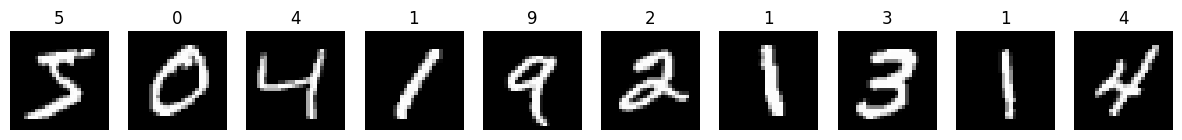

In [ ]:
#TODO
fig, axes = plt.subplots(1, 10, figsize=(15, 2))
for i, ax in enumerate(axes):
    ...
    ax.set_title(...)
    ax.axis("off")

#### b) Defining a CNN (5 points)

Explain what the following CNN instantiation is doing. Make sure to describe each layer, loss function, and the optimizer. 

In [123]:
## Standard Parameters 
out_dim = 10 # Why does this need to be 10?  
epochs = 20

In [124]:
cnn = tf.keras.Sequential([
    tf.keras.layers.Conv2D(8, 5, activation="relu", input_shape=(28, 28, 1)),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(out_dim, activation="softmax")
])
cnn.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])



/Users/varunvaranasi/.local/share/virtualenvs/Cengiz-xWqTNzGq/lib/python3.10/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
history = cnn.fit(x_train, y_train, epochs=5, validation_data=(x_test, y_test), verbose=1)
test_loss, test_acc = cnn.evaluate(x_test, y_test, verbose=0)
print(f"Test accuracy: {test_acc:.4f}")

#### c) Comparing CNN parameterizations (5 points)

Using the code snippets provided, train and save the accuracy of two different CNN parameterizations. Explain how the parameterizations differ and plot the validation accuracy over the course of training for each model on the same plot.

In [ ]:
#TODO

#### d) Analyze Learned Filters (15 points)

In this problem, we want you to visualize the learned filters of the CNN for the better performing model from the previous section. Use .get_weights() to capture the filters from the correct layer of your CNN. Comment on the observed patterns. What do you notice?

Text(0.5, 0.98, 'Learned Conv2D Filters')

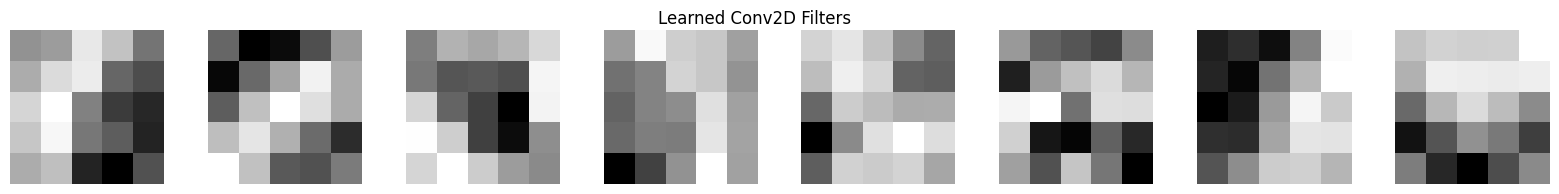

In [ ]:
#TODO
filters = ...

fig, axes = plt.subplots(1, 8, figsize=(20, 2))
for i, ax in enumerate(axes):
    ax.imshow(..., cmap="gray")
    ax.axis("off")
plt.suptitle("Learned Conv2D Filters")
plt.show()

## 4) Wrap-up (10 points)
Briefly reflect: which task was hardest to get working, and why? How does this inform your initial thoughts for the final project?